# Homework 4: Vanilla Diffusion

Every model so far has taken an image and produced an answer. This one takes noise and
produces an image. The idea has two halves:

1. **Forward.** Add a little noise to an image, many times, until only noise is left. Nothing
   is learnt here.
2. **Reverse.** Train a network to predict the noise in a noisy image. Then start from pure
   noise and remove the predicted noise one step at a time, until a new image appears.

You will build the original method, DDPM ([Ho et al., 2020](https://arxiv.org/abs/2006.11239)), on
MNIST digits shrunk to 16x16.
They are still easy to read, and the smaller images are what makes this practical on a CPU.

| Part | What | Marks |
|---|---|---|
| 1 | The noise schedule (Task 1) | **implementation** |
| 2 | Adding noise in one jump (Task 2) | **implementation, results** |
| 3 | Training the noise predictor (Task 3) | **implementation, results** |
| 4 | Generating digits (Tasks 4 and 5) | **implementation, results** |
| 5 | Three questions | **written answers** |

Marking is 20 percent implementation, 20 percent results, 10 percent written answers.

**How to work.** Search for `TODO`. There are five. In each one, replace the
`raise NotImplementedError` line with your code, then run the self-check below it. Do not
start the next task until the self-check prints `PASSED`.

**Runtime.** The notebook picks the GPU if there is one and the CPU if not, so there is
nothing to change. On a slow 2-core CPU the whole notebook takes about 16 minutes, nearly all of
it training. A GPU will be much faster, and on Colab you can turn one on under
Runtime > Change runtime type.

---
# Part 0. Setup

In [1]:
import math
import time

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

# Uses the GPU if there is one, otherwise the CPU. Nothing else needs changing.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0)
print("running on:", device)

T = 1000              # number of diffusion steps
IMAGE_SIZE = 16       # MNIST shrunk from 28x28
BATCH_SIZE = 64
EPOCHS = 10           # set to 1 to test that everything runs, then set it back
LEARNING_RATE = 1e-3

running on: cuda


60000 images, batch shape (64, 1, 16, 16), pixel range [-1, 1]


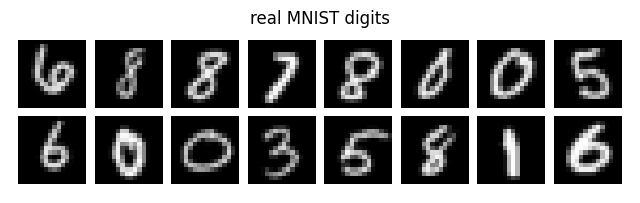

In [2]:
# Pixels start in [0, 1]. We rescale them to [-1, 1] so that they match the
# zero-centred noise they will be mixed with.
to_tensor = transforms.Compose([transforms.Resize(IMAGE_SIZE), transforms.ToTensor(),
                                transforms.Normalize([0.5], [0.5])])
train_data = datasets.MNIST("./data", train=True, download=True, transform=to_tensor)
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)


def show_images(images, title="", per_row=8):
    """Draw a batch of images in [-1, 1] as one grid."""
    images = images.detach().cpu().clamp(-1, 1) * 0.5 + 0.5
    rows = math.ceil(len(images) / per_row)
    plt.figure(figsize=(per_row, rows + 0.4))
    plt.imshow(make_grid(images, nrow=per_row, pad_value=1).permute(1, 2, 0))
    plt.title(title)
    plt.axis("off")
    plt.show()


sample_batch, _ = next(iter(train_loader))
print(f"{len(train_data)} images, batch shape {tuple(sample_batch.shape)}, "
      f"pixel range [{sample_batch.min():.0f}, {sample_batch.max():.0f}]")
show_images(sample_batch[:16], "real MNIST digits")

---
# Part 1. The noise schedule

At each step `t` we add a little noise. A schedule says how much:

```
beta_t                                    noise added at step t
alpha_t     = 1 - beta_t                  signal kept at step t
alpha_bar_t = alpha_0 * alpha_1 * ... * alpha_t     signal left after every step up to t
```

`alpha_bar_t` is the number to remember. It starts close to 1, a clean image, and ends close to
0, pure noise. Steps run from `0` to `T - 1`, the way Python counts. The paper counts from 1.

## Task 1: build the schedule

Use the linear schedule from the paper: `beta` rises evenly from `0.0001` to `0.02`.

In [3]:
def make_schedule(T):
    """Linear noise schedule. Returns betas, alphas and alpha_bars, each of shape (T,)."""
    # ==================== YOUR CODE HERE ====================
    # TODO (Task 1): make the three tensors.
    betas = torch.linspace(0.0001, 0.02, T)
    alphas = 1 - betas
    alpha_bars = torch.cumprod(alphas, dim=0)
    #raise NotImplementedError("Task 1")
    # ========================================================
    return betas, alphas, alpha_bars


betas, alphas, alpha_bars = [s.to(device) for s in make_schedule(T)]

### Self-check, Task 1

Task 1 PASSED


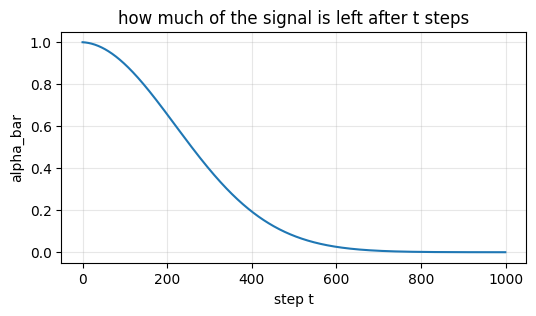

In [4]:
assert betas.shape == alphas.shape == alpha_bars.shape == (T,), "each tensor needs shape (T,)"
assert abs(betas[0] - 1e-4) < 1e-6 and abs(betas[-1] - 0.02) < 1e-6, "betas run from 0.0001 to 0.02"
assert torch.allclose(betas + alphas, torch.ones(T, device=device)), "alphas should be 1 - betas"
assert abs(alpha_bars[0] - alphas[0]) < 1e-6, "alpha_bars should start at alphas[0]"
assert abs(alpha_bars[-1] / alphas.prod() - 1) < 0.01, "alpha_bars[-1] should be the product of all alphas"
print("Task 1 PASSED")

plt.figure(figsize=(6, 3))
plt.plot(alpha_bars.cpu())
plt.xlabel("step t")
plt.ylabel("alpha_bar")
plt.title("how much of the signal is left after t steps")
plt.grid(alpha=0.3)
plt.show()

---
# Part 2. Adding noise in one jump

To noise an image up to step `t` we could add noise `t` times, but there is no need. A sum of
Gaussians is also a Gaussian, so we can jump straight there:

```
x_t = sqrt(alpha_bar_t) * x_0  +  sqrt(1 - alpha_bar_t) * noise
```

## Task 2: `q_sample`

**Watch the shapes.** Each image in a batch has its own step, so `t` has shape `(N,)` and so
does `alpha_bars[t]`. The images have shape `(N, 1, 16, 16)`. Reshape to `(N, 1, 1, 1)` before
multiplying, so that each image is scaled by its own number.

In [5]:
def q_sample(x0, t, noise):
    """Jump straight from clean images to noise level t.

    x0:    clean images, shape (N, 1, 16, 16)
    t:     one step per image, shape (N,)
    noise: standard normal noise, same shape as x0
    Returns the noisy images x_t, same shape as x0.
    """
    # ==================== YOUR CODE HERE ====================
    # TODO (Task 2): look up alpha_bars for each image, reshape it with
    # .view(-1, 1, 1, 1), then apply the formula above to get x_t.
    a = alpha_bars[t].view(-1, 1, 1, 1)
    x_t = a.sqrt() * x0 + (1 - a).sqrt() * noise
    #raise NotImplementedError("Task 2")
    # ========================================================
    return x_t

### Self-check, Task 2

In [6]:
clean = sample_batch[:8].to(device)
noise = torch.randn_like(clean)


def steps(value, count=8):
    return torch.full((count,), value, device=device)


assert q_sample(clean, steps(0), noise).shape == clean.shape, "x_t must have the shape of x0"
assert (q_sample(clean, steps(0), noise) - clean).abs().max() < 0.06, "at t = 0 the image should be almost untouched"
assert (q_sample(clean, steps(T - 1), noise) - noise).abs().max() < 0.05, "at t = T - 1 only noise should be left"

# Each image must use its own step: noising a batch must match noising one image at a time.
mixed_t = torch.arange(8, device=device) * 140
together = q_sample(clean, mixed_t, noise)
one_by_one = torch.cat([q_sample(clean[i:i + 1], mixed_t[i:i + 1], noise[i:i + 1]) for i in range(8)])
assert torch.allclose(together, one_by_one, atol=1e-5), "each image must use its own t"

# With data of variance 1, x_t must keep variance 1 at every step. That is why both terms have a sqrt.
data = torch.randn(4096, 1, 8, 8, device=device)
for t in (100, 500, 900):
    variance = q_sample(data, steps(t, 4096), torch.randn_like(data)).var().item()
    assert abs(variance - 1) < 0.03, f"variance at t={t} is {variance:.3f}, it should stay at 1"
print("Task 2 PASSED")

Task 2 PASSED


**Result.** One digit at seven points along the schedule, with the same noise each time.

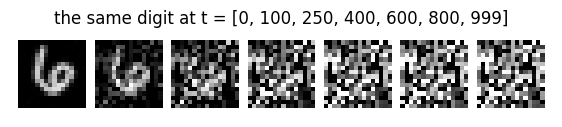

t =   0   alpha_bar = 0.9999
t = 100   alpha_bar = 0.8951
t = 250   alpha_bar = 0.5214
t = 400   alpha_bar = 0.1936
t = 600   alpha_bar = 0.0256
t = 800   alpha_bar = 0.0015
t = 999   alpha_bar = 0.0000


In [7]:
ladder = [0, 100, 250, 400, 600, 800, 999]
digit = sample_batch[:1].to(device)
noise = torch.randn_like(digit)
noised = [q_sample(digit, steps(t, 1), noise) for t in ladder]
show_images(torch.cat(noised), f"the same digit at t = {ladder}", per_row=len(ladder))

for t in ladder:
    print(f"t = {t:>3}   alpha_bar = {alpha_bars[t]:.4f}")

---
# Part 3. Training the noise predictor

The network sees a noisy image `x_t` and the step `t`, and predicts the noise that was added.

The network is a small U-Net and it is given to you, so there is no `TODO` in the next cell. Two
things to notice:

- **It is told `t`.** One network handles all 1000 noise levels, and `t` says which one it is
  looking at. `t` becomes a vector of sines and cosines, the same idea as the positional
  encoding in HW3, and that vector is added inside every `ResBlock`.
- **The output has the same shape as the input,** one noise value per pixel. The image shrinks
  from 16x16 to 4x4 and grows back, with skip connections carrying the detail across.

In [8]:
def timestep_embedding(t, dim):
    """Turn steps of shape (N,) into sine and cosine vectors of shape (N, dim)."""
    half = dim // 2
    frequencies = torch.exp(-math.log(10000.0) * torch.arange(half, device=t.device) / half)
    angles = t[:, None] * frequencies[None, :]
    return torch.cat([torch.cos(angles), torch.sin(angles)], dim=-1)


class ResBlock(nn.Module):
    """Two convolutions, with the timestep embedding added in between."""

    def __init__(self, in_channels, out_channels, embedding_dim):
        super().__init__()
        self.conv1 = nn.Sequential(nn.GroupNorm(8, in_channels), nn.SiLU(),
                                   nn.Conv2d(in_channels, out_channels, 3, padding=1))
        self.project = nn.Sequential(nn.SiLU(), nn.Linear(embedding_dim, out_channels))
        self.conv2 = nn.Sequential(nn.GroupNorm(8, out_channels), nn.SiLU(),
                                   nn.Conv2d(out_channels, out_channels, 3, padding=1))
        self.skip = nn.Conv2d(in_channels, out_channels, 1)

    def forward(self, x, embedding):
        h = self.conv1(x)
        h = h + self.project(embedding)[:, :, None, None]
        return self.conv2(h) + self.skip(x)


class UNet(nn.Module):
    """Predicts the noise in x_t. Input and output have shape (N, 1, 16, 16)."""

    def __init__(self, base=32, embedding_dim=128):
        super().__init__()
        self.embedding_dim = embedding_dim
        self.time_mlp = nn.Sequential(nn.Linear(embedding_dim, embedding_dim), nn.SiLU(),
                                      nn.Linear(embedding_dim, embedding_dim))
        self.first = nn.Conv2d(1, base, 3, padding=1)
        self.down1 = ResBlock(base, base, embedding_dim)           # 16x16
        self.down2 = ResBlock(base, base * 2, embedding_dim)       # 8x8
        self.middle = ResBlock(base * 2, base * 2, embedding_dim)  # 4x4
        self.up2 = ResBlock(base * 4, base, embedding_dim)         # 8x8
        self.up1 = ResBlock(base * 2, base, embedding_dim)         # 16x16
        self.last = nn.Conv2d(base, 1, 3, padding=1)

    def forward(self, x, t):
        e = self.time_mlp(timestep_embedding(t, self.embedding_dim))
        h1 = self.down1(self.first(x), e)
        h2 = self.down2(F.avg_pool2d(h1, 2), e)
        middle = self.middle(F.avg_pool2d(h2, 2), e)
        u2 = self.up2(torch.cat([F.interpolate(middle, scale_factor=2), h2], dim=1), e)
        u1 = self.up1(torch.cat([F.interpolate(u2, scale_factor=2), h1], dim=1), e)
        return self.last(u1)


model = UNet().to(device)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

298,785 parameters


## Task 3: the training loss

This is Algorithm 1 in the paper. For a batch of clean images:

1. Pick a random step `t` for each image, from `0` to `T - 1`.
2. Draw noise with the same shape as the images.
3. Noise the images to `x_t` with your `q_sample`.
4. Ask the model to predict the noise from `x_t` and `t`.
5. Return the mean squared error between the predicted noise and the real noise.

In [9]:
def diffusion_loss(model, x0):
    """The DDPM training loss for one batch of clean images, shape (N, 1, 16, 16)."""
    # ==================== YOUR CODE HERE ====================
    # TODO (Task 3): follow the five steps above and store the result in loss.
    # Useful: torch.randint, torch.randn_like, F.mse_loss.
    # Create t on the same device as the images: device=x0.device
    t = torch.randint(0, T, (x0.shape[0],), device=x0.device)
    noise = torch.randn_like(x0)
    x_t = q_sample(x0, t, noise)
    noise_pred = model(x_t, t)
    loss = F.mse_loss(noise_pred, noise)
    # raise NotImplementedError("Task 3")
    # ========================================================
    return loss

### Self-check, Task 3

Two stand-in models replace the real one here. `ZeroModel` always predicts zero, so its loss must
be about 1, the variance of the noise. `CheatingModel` knows the clean images, so it can work out
the exact noise and its loss must be about 0. That only happens if you compared against the same
noise, and passed the same `t`, that you used to make `x_t`.

In [10]:
class ZeroModel(nn.Module):
    def forward(self, x_t, t):
        return torch.zeros_like(x_t)


class CheatingModel(nn.Module):
    def __init__(self, x0):
        super().__init__()
        self.x0 = x0

    def forward(self, x_t, t):
        self.t = t
        zeros = torch.zeros_like(x_t)
        signal = q_sample(self.x0, t, zeros)                      # the x_0 part of x_t
        noise_size = q_sample(zeros, t, torch.ones_like(x_t))     # what the noise was scaled by
        return (x_t - signal) / noise_size


fake_images = torch.randn(20000, 1, 2, 2, device=device)   # tiny, so that this runs quickly

zero_loss = diffusion_loss(ZeroModel(), fake_images).item()
assert abs(zero_loss - 1) < 0.05, f"a model that predicts zero should score about 1, got {zero_loss:.3f}"

cheat = CheatingModel(fake_images)
cheat_loss = diffusion_loss(cheat, fake_images).item()
assert cheat_loss < 1e-3, f"a perfect model should score about 0, got {cheat_loss:.3f}"

assert cheat.t.shape == (20000,), "draw one step per image, not one for the whole batch"
assert cheat.t.min() == 0 and cheat.t.max() == T - 1, "t should cover 0 to T - 1"
print("Task 3 PASSED")

Task 3 PASSED


**Training.** The loop is given. One line prints per epoch, and the first line tells you how long
the rest will take.

In [11]:
optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
losses = []
start = time.time()

for epoch in range(EPOCHS):
    for images, _ in train_loader:
        loss = diffusion_loss(model, images.to(device))
        optimiser.zero_grad()
        loss.backward()
        optimiser.step()
        losses.append(loss.item())

    average = sum(losses[-len(train_loader):]) / len(train_loader)
    print(f"epoch {epoch + 1}/{EPOCHS}   loss {average:.4f}   {time.time() - start:.0f}s")

epoch 1/10   loss 0.0596   71s
epoch 2/10   loss 0.0384   139s
epoch 3/10   loss 0.0358   210s
epoch 4/10   loss 0.0348   281s
epoch 5/10   loss 0.0342   354s
epoch 6/10   loss 0.0334   427s
epoch 7/10   loss 0.0331   501s
epoch 8/10   loss 0.0322   574s
epoch 9/10   loss 0.0323   649s
epoch 10/10   loss 0.0322   747s


**Result.** The training loss.

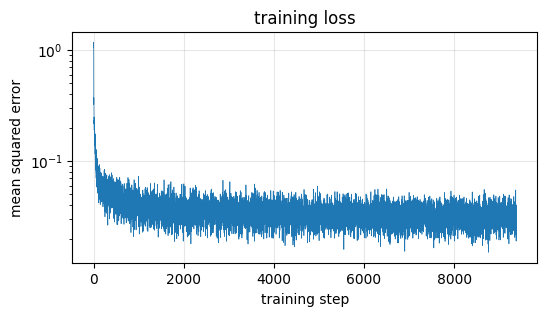

final loss, averaged over the last 100 steps: 0.0321


In [12]:
plt.figure(figsize=(6, 3))
plt.plot(losses, linewidth=0.5)
plt.yscale("log")
plt.xlabel("training step")
plt.ylabel("mean squared error")
plt.title("training loss")
plt.grid(alpha=0.3)
plt.show()

print(f"final loss, averaged over the last 100 steps: {sum(losses[-100:]) / 100:.4f}")

---
# Part 4. Generating digits

Generating runs the chain backwards: start from pure noise at `t = T - 1` and step down to
`t = 0`, using the model's noise prediction at every step.

## Task 4: one step back

```
mean    = (x_t - beta_t / sqrt(1 - alpha_bar_t) * noise_pred) / sqrt(alpha_t)
x_{t-1} = mean + noise_scale * sqrt(beta_t) * fresh_noise
```

**Two details.** At `t = 0` return the `mean` with no fresh noise, because this is the final
image and noise there would stay as visible grain. And `noise_scale` stays at 1 until Question 3.

In [13]:
def ddpm_step(x_t, t, noise_pred, noise_scale=1.0):
    """One step back, from x_t to x_{t-1}.

    x_t:         current images, shape (N, 1, 16, 16)
    t:           the current step, a plain int, the same for the whole batch
    noise_pred:  the model's prediction, same shape as x_t
    noise_scale: multiplies the fresh noise
    Returns the images at step t - 1.
    """
    # ==================== YOUR CODE HERE ====================
    # TODO (Task 4): compute the mean, then return it as it is when t == 0.
    # Otherwise add the fresh noise. torch.randn_like gives you fresh_noise.
    beta_t = betas[t]
    alpha_t = alphas[t]
    alpha_bar_t = alpha_bars[t]
    mean = (x_t - beta_t / torch.sqrt(1 - alpha_bar_t) * noise_pred) / torch.sqrt(alpha_t)
    if t == 0:
        return mean
    return mean + noise_scale * torch.sqrt(beta_t) * torch.randn_like(x_t)
    # raise NotImplementedError("Task 4")
    # ========================================================

### Self-check, Task 4

With a flat image and a flat noise prediction, the answer can be checked against known numbers.

In [14]:
flat = torch.ones(1024, 1, IMAGE_SIZE, IMAGE_SIZE, device=device)

#         t: expected mean of the result
known = {999: 0.9899, 500: 0.9945, 20: 0.994, 1: 0.992, 0: 0.9901}

for t, expected_mean in known.items():
    result = ddpm_step(flat, t, flat)
    expected_std = 0 if t == 0 else betas[t].sqrt().item()
    assert result.shape == flat.shape, "the result must have the shape of x_t"
    assert abs(result.mean().item() - expected_mean) < 0.003, \
        f"at t={t} the mean should be {expected_mean}, got {result.mean().item():.4f}"
    assert abs(result.std().item() - expected_std) < 0.003, \
        f"at t={t} the fresh noise should have std {expected_std:.4f}, got {result.std().item():.4f}"

quiet = ddpm_step(flat, 500, flat, noise_scale=0.0)
assert quiet.std().item() < 1e-5, "noise_scale=0 should remove the fresh noise"
print("Task 4 PASSED")

Task 4 PASSED


## Task 5: the sampling loop

This is Algorithm 2 in the paper. Start from pure noise, then for `t = T - 1, T - 2, ..., 0`:

1. Make a tensor of shape `(count,)` filled with `t`, because the model wants one step per image.
2. Ask the model for its noise prediction.
3. Take one `ddpm_step`, passing `noise_scale` along.
4. When `t` is a multiple of 100, add `x.cpu()` to `snapshots`. The figure below uses these.

In [15]:
@torch.no_grad()
def sample_ddpm(model, count, noise_scale=1.0):
    """Generate images. Returns the images, shape (count, 1, 16, 16), and the snapshots."""
    snapshots = []
    # ==================== YOUR CODE HERE ====================
    # TODO (Task 5): start x as pure noise with torch.randn. Give it the shape of
    # the images in the docstring, and put it on the device. Then write the loop above.
    x = torch.randn(count, 1, IMAGE_SIZE, IMAGE_SIZE, device=device)
    for t in range(T - 1, -1, -1):
        t_batch = torch.full((count,), t, device=device, dtype=torch.long)
        noise_pred = model(x, t_batch)
        x = ddpm_step(x, t, noise_pred, noise_scale)
        if t % 100 == 0:
            snapshots.append(x.cpu())
    # raise NotImplementedError("Task 5")
    # ========================================================
    return x, snapshots

### Self-check, Task 5

A stand-in model predicts zero noise and records every call it receives.

In [16]:
class RecordingModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.calls = []
        self.first_x = None

    def forward(self, x, t):
        if self.first_x is None:
            self.first_x = x.clone()
        self.calls.append(t)
        return torch.zeros_like(x)


fake = RecordingModel()
images, snapshots = sample_ddpm(fake, 8)
assert images.shape == (8, 1, IMAGE_SIZE, IMAGE_SIZE), f"wrong shape: {tuple(images.shape)}"
assert abs(fake.first_x.std().item() - 1) < 0.1, "start from pure noise"
assert len(fake.calls) == T, f"expected {T} model calls, got {len(fake.calls)}"
assert fake.calls[0].shape == (8,), "give the model one step per image"
assert [t[0].item() for t in fake.calls] == list(range(T - 1, -1, -1)), "walk t from T - 1 down to 0"
assert len(snapshots) == 10, f"expected 10 snapshots, got {len(snapshots)}"
assert 200 < images.std().item() < 240, "x must be updated with the result of ddpm_step at every step"

# With noise_scale=0 only the starting noise is left, so the result is a scaled copy of it.
fake = RecordingModel()
images, _ = sample_ddpm(fake, 8, noise_scale=0.0)
assert (images / fake.first_x).std().item() < 1e-2, "pass noise_scale along to ddpm_step"
print("Task 5 PASSED")

Task 5 PASSED


**Result.** Digits your model made from pure noise. None of these exist in MNIST.

64 images in 12s, 1000 model calls


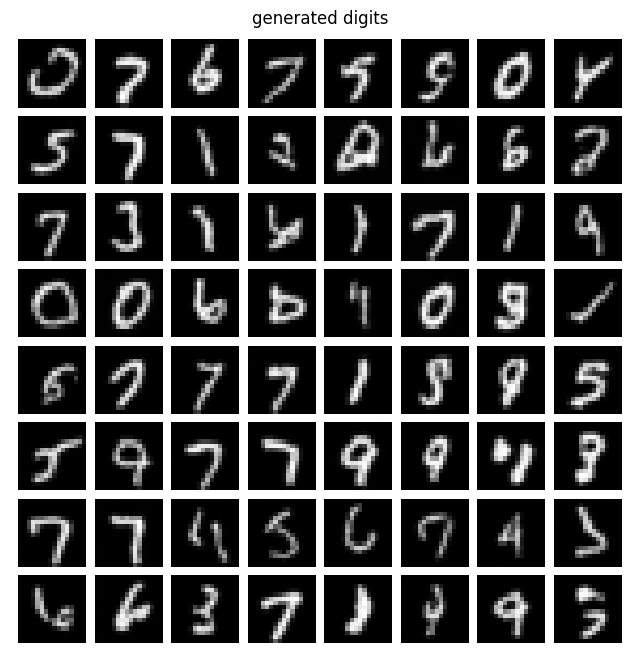

In [17]:
torch.manual_seed(0)
start = time.time()
generated, snapshots = sample_ddpm(model, 64)
print(f"64 images in {time.time() - start:.0f}s, {T} model calls")
show_images(generated, "generated digits")

**Result.** One sample as it forms. Read left to right, from `t = 900` down to `t = 0`.

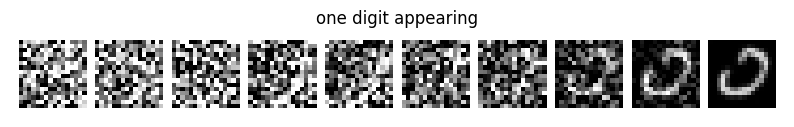

In [18]:
show_images(torch.cat([frame[:1] for frame in snapshots]), "one digit appearing", per_row=len(snapshots))

**Result, for Question 3.** The same trained model with no fresh noise during sampling.

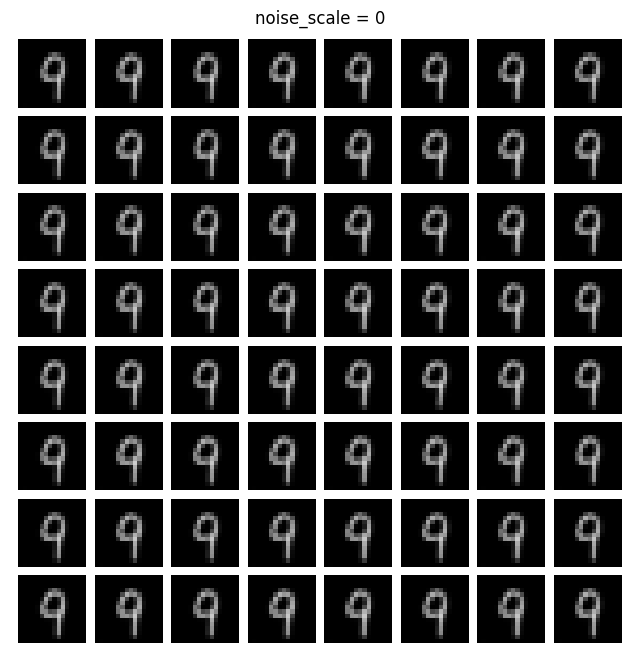

In [19]:
torch.manual_seed(0)
no_noise, _ = sample_ddpm(model, 64, noise_scale=0.0)
show_images(no_noise, "noise_scale = 0")

---
# Part 5. Three questions

Answer in your own words, **citing your own numbers and figures**. An answer that would read the
same if you had run nothing scores zero.

### Question 1

From your figure in Part 2, at about which step does the digit stop being recognisable, and
what is `alpha_bar` there?

Now run `make_schedule(100)[2][-1]` to get the final `alpha_bar` with only 100 steps and the same
range of `beta`. Sampling starts from pure noise. Why would this shorter schedule be a problem?

In [20]:
# Final alpha_bar with only 100 steps and the same beta range (for Question 1)
make_schedule(100)[2][-1]

tensor(0.3636)

In my noise ladder (t = 0, 100, 250, 400, 600, 800, 999), the "6" is still clearly visible at t = 100 (alpha_bar = 0.895), only faintly visible at t = 250 (alpha_bar = 0.521), and no longer recognisable by about **t = 400, where alpha_bar = 0.194**. From t = 600 on (alpha_bar = 0.026) it looks like pure noise.

`make_schedule(100)[2][-1]` gives **alpha_bar ≈ 0.364**, versus about 0.00004 for T = 1000. With only 100 steps and the same beta range, the forward process never reaches pure noise: x_T still contains sqrt(0.364) ≈ 0.60 of the original image. But sampling starts from pure Gaussian noise, which is not what x_T looks like during training. The model has never been trained on inputs like pure noise at t = T, so the start of the reverse chain does not match the training distribution and the samples would be poor. With 1000 steps alpha_bar is ≈ 0, so x_T really is pure noise and sampling from N(0, I) matches training.

### Question 2

What was your final loss? A model that always predicts zero scores about 1: why exactly that
number? One network handles all 1000 noise levels. How does being told `t` help it?

My final loss was **0.0321** (averaged over the last 100 steps), down from 0.0596 after the first epoch.

A model that always predicts zero gets loss E[(0 − ε)²] = E[ε²]. The target noise ε is drawn from a standard normal, whose variance is 1 and mean is 0, so E[ε²] = Var(ε) + (E[ε])² = 1 exactly (averaged over all pixels). My model is about 30× better than this baseline.

Being told t tells the network how x_t was mixed: x_t = sqrt(alpha_bar_t)·x0 + sqrt(1 − alpha_bar_t)·ε. At small t (alpha_bar ≈ 1) x_t is almost the clean image, so the noise is small and the model must pick out faint noise from a digit. At large t (alpha_bar ≈ 0) x_t is almost all noise, so the best prediction of ε is close to x_t itself. These require very different behaviour, and without t the network would have to guess the noise level from the image alone. The timestep embedding added in every ResBlock lets one network act as a different denoiser for each noise level.

### Question 3

Compare your `noise_scale = 0` figure with your normal samples. What changed? Each step of
sampling predicts the noise and subtracts it, so why does adding fresh noise back help?

My normal samples (noise_scale = 1) are a varied set of digits: 0, 1, 3, 5, 6, 7, 9 etc., with different shapes and stroke widths. With **noise_scale = 0 all 64 samples collapsed to almost the same image**: a faint, dimmer, blurrier "9", even though each sample started from different random noise. So diversity disappeared and image quality dropped.

Each step predicts the noise and subtracts it, but the prediction is only the *average* (expected) noise given x_t, so each deterministic step moves x towards the mean of all images consistent with x_t. Repeating this 1000 times pulls every sample towards the same average-looking, low-contrast digit. DDPM's reverse process is a stochastic process: x_{t-1} is drawn from a Gaussian with mean `mean` and variance beta_t. Adding fresh noise sqrt(beta_t)·z samples from that distribution instead of always taking its centre, which keeps the variance of x at the level the model was trained on and lets each sample commit to a different digit. That is why noise_scale = 1 gives sharp and diverse digits.

---
# Submission checklist

- [ ] `Restart and run all` finishes with no errors
- [ ] All five self-checks print `PASSED`
- [ ] These figures are visible: the noise ladder, the loss curve, the generated digits,
      one digit appearing, and `noise_scale = 0`
- [ ] All three questions are answered, citing your own numbers

Then download the `.ipynb` and submit it.